# Proyecto de predicción de siniestralidad vial en Bogotá
## Diagnóstico inicial de datos

**Objetivo:** verificar la estructura y calidad de los registros del archivo **ACCIDENTE.csv** con el propósito de identificar las características de la información disponible y preparar la exploración de los datos correspondiente a la Entrega 1 del proyecto.

Los resultados obtenidos durante la exploración permiten reconocer la distribución de los registros, identificar valores faltantes y detectar posibles inconsistencias en la información, por lo que su interpretación debe considerar la calidad y cobertura de los datos disponibles.

### 1. Carga del archivo CSV y consulta de su estructura

Se utiliza `utf-8-sig` para reconocer el encabezado correctamente, ya que el CSV original tiene marca BOM de UTF-8, no se modifica el archivo fuente.

In [ ]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import csv
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
ARCHIVO = Path("/ACCIDENTE.csv")

with ARCHIVO.open("r", encoding="utf-8-sig", newline="") as archivo:
    lector = csv.DictReader(archivo)
    columnas = lector.fieldnames or []
    registros = list(lector)

print(f"Total de registros: {len(registros)}")
print(f"Total de columnas: {len(columnas)}")

Total de registros: 801967
Total de columnas: 23


### 2. Vista previa de datos

Se muestran solo cinco filas y seis variables clave, para observar la información sin imprimir las 23 columnas completas.

In [ ]:
columnas_clave = ["CODIGO_ACCIDENTE","FECHA_OCURRENCIA_ACC","LOCALIDAD","GRAVEDAD","CLASE_ACC","BARRIO"]

tabla = pd.DataFrame(registros)
display(tabla[columnas_clave].head(5))

,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,LOCALIDAD,GRAVEDAD,CLASE_ACC,BARRIO
0,4484660,2017/06/12 00:00:00+00,ENGATIVA,SOLO DANOS,CHOQUE,BONANZA
1,449558,2012/12/15 00:00:00+00,CHAPINERO,SOLO DANOS,CHOQUE,EL REFUGIO
2,513150,2014/10/26 00:00:00+00,ENGATIVA,CON HERIDOS,ATROPELLO,LAS FERIAS
3,443270,2012/10/15 00:00:00+00,FONTIBON,SOLO DANOS,CHOQUE,CIUDAD HAYUELOS
4,4412699,2015/05/11 00:00:00+00,CIUDAD BOLIVAR,SOLO DANOS,CHOQUE,PERDOMO ALTO


### 3. Calidad de los datos

Se revisa la existencia de celdas vacías, códigos de accidente repetidos y/o valores especiales como `SIN_NMG`. Estos últimos no se cuentan automáticamente como vacíos, su significado debe validarse en el diccionario oficial de datos.

In [ ]:
# Preparación de los datos
df = pd.DataFrame(registros)
df = df.replace(r"^\s*$", pd.NA, regex=True)

# Identificación de valores vacíos
vacios = df.isna().sum()
tabla_vacios = pd.DataFrame({
    "Columna": vacios.index,
    "Valores vacíos": vacios.values,
    "Porcentaje (%)": (vacios.values / len(df) * 100).round(2)
})
tabla_vacios = tabla_vacios[tabla_vacios["Valores vacíos"] > 0].sort_values("Valores vacíos", ascending=False)

print("1. Valores vacíos por columna")
display(tabla_vacios)

1. Valores vacíos por columna


,Columna,Valores vacíos,Porcentaje (%)
21,MVINOMBRE,6886,0.86
19,PK_CALZADA,1597,0.20
18,CIV,1374,0.17
12,CLASE_ACC,281,0.04
20,BARRIO,73,0.01
11,GRAVEDAD,7,0.00
6,HORA_OCURRENCIA_ACC,1,0.00
7,ANO_OCURRENCIA_ACC,1,0.00
8,MES_OCURRENCIA_ACC,1,0.00
14,MUNICIPIO,1,0.00


In [ ]:
# Identificación de registros duplicados
codigos = df["CODIGO_ACCIDENTE"].dropna().str.strip()
duplicados = codigos.duplicated().sum()

# Identificación de nombres no especificados
sin_nombre = (df["MVINOMBRE"].fillna("").str.strip().str.upper().eq("SIN_NMG").sum())

# Resumen de calidad de datos
resumen = pd.DataFrame({
    "Indicador": ["Total de registros","Códigos de accidente duplicados","Registros con MVINOMBRE = SIN_NMG"],
    "Cantidad":[len(df),duplicados,sin_nombre]
})
print("Resumen de calidad de datos")
display(resumen)

Resumen de calidad de datos


,Indicador,Cantidad
0,Total de registros,801967
1,Códigos de accidente duplicados,0
2,Registros con MVINOMBRE = SIN_NMG,377437


### 4. Fechas y categorías

Este análisis revela qué años y localidades aparecen en el archivo de prueba, las fechas se interpretan desde los diez primeros caracteres (AAAA/MM/DD) para evitar problemas con el sufijo de zona horaria del CSV las horas se analizarán después.

In [ ]:
# Análisis de fechas
fechas = pd.to_datetime(df["FECHA_OCURRENCIA_ACC"].astype("string").str[:10].str.replace("/", "-"),format="%Y-%m-%d",errors="coerce")
tabla_fechas = pd.DataFrame({
    "Total de registros": [len(df)],
    "Fechas válidas": [fechas.notna().sum()],
    "Fechas no válidas": [fechas.isna().sum()],
    "Fecha inicial": [fechas.min().date() if fechas.notna().any() else "Sin datos"],
    "Fecha final": [fechas.max().date() if fechas.notna().any() else "Sin datos"]
})

print("Resumen de fechas")
display(tabla_fechas)

Resumen de fechas


,Total de registros,Fechas válidas,Fechas no válidas,Fecha inicial,Fecha final
0,801967,801966,1,2001-01-15,2025-06-19


In [ ]:
# Distribución de variables
columnas_analisis = ["LOCALIDAD", "GRAVEDAD", "CLASE_ACC"]
for columna in columnas_analisis:
    datos = (df[columna].fillna("").astype(str).str.strip().replace("", "(vacío)"))
    conteos = datos.value_counts()
    tabla_distribucion = pd.DataFrame({
        "Categoría": conteos.index,
        "Cantidad": conteos.values,
        "Porcentaje (%)": (conteos.values / len(df) * 100).round(2)
    })

    print(f"Distribución de {columna}")
    display(tabla_distribucion)

Distribución de LOCALIDAD


,Categoría,Cantidad,Porcentaje (%)
0,KENNEDY,91594,11.42
1,USAQUEN,83828,10.45
2,SUBA,82859,10.33
3,ENGATIVA,79281,9.89
4,FONTIBON,62650,7.81
5,CHAPINERO,59197,7.38
6,PUENTE ARANDA,57702,7.20
7,TEUSAQUILLO,45016,5.61
8,BARRIOS UNIDOS,43613,5.44
9,BOSA,30480,3.80


Distribución de GRAVEDAD


,Categoría,Cantidad,Porcentaje (%)
0,SOLO DANOS,524017,65.34
1,CON HERIDOS,265525,33.11
2,CON MUERTOS,12418,1.55
3,(vacío),7,0.00


Distribución de CLASE_ACC


,Categoría,Cantidad,Porcentaje (%)
0,CHOQUE,669170,83.44
1,ATROPELLO,91661,11.43
2,CAIDA DE OCUPANTE,16794,2.09
3,OTRO,9958,1.24
4,VOLCAMIENTO,9645,1.20
5,AUTOLESION,4382,0.55
6,(vacío),281,0.04
7,INCENDIO,76,0.01


### 5. Visualización de registros de accidentes por localidad
Se presenta la distribución de los accidentes de tránsito registrados en las diferentes localidades de Bogotá, con el propósito de identificar cuáles presentan una mayor cantidad de registros y facilitar la comparación de los resultados mediante un gráfico de barras.

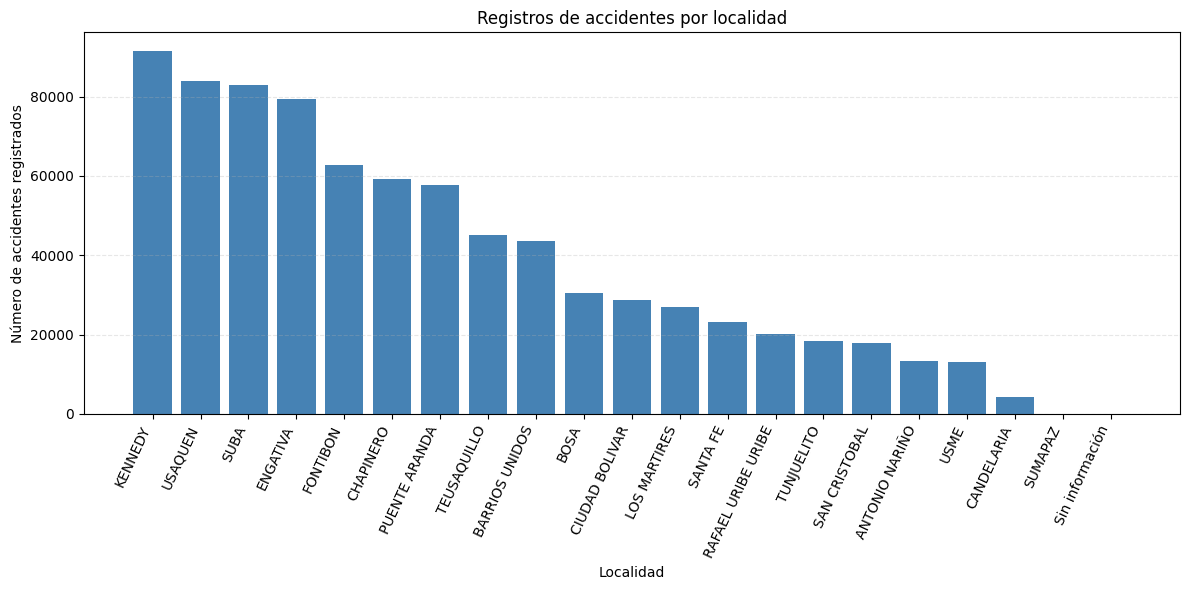

In [ ]:
# Agrupación de accidentes por localidad
frecuencias = (df["LOCALIDAD"].fillna("Sin información").replace("", "Sin información").value_counts())

# Configuración del gráfico
plt.figure(figsize=(12, 6))
plt.bar(frecuencias.index,frecuencias.values,color="steelblue")
plt.title("Registros de accidentes por localidad")
plt.xlabel("Localidad")
plt.ylabel("Número de accidentes registrados")
plt.xticks(rotation=65, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### 6. Comportamiento temporal de los siniestros

 Este apartado queremos identificar cómo ha cambiado la cantidad de siniestros a lo largo del tiempo, si existen aumentos o disminuciones y qué patrones temporales pueden resultar útiles para nuestro modelo predictivo.

Agruparemos inicialmente los datos por año solo con fines exploratorios. Esto no significa que el modelo ni el futuro tablero deban limitarse a periodos anuales.

In [ ]:
# Preparación de los datos
datos = pd.DataFrame(registros)
fechas = pd.to_datetime(datos["FECHA_OCURRENCIA_ACC"].astype(str).str[:10].str.replace("/", "-", regex=False),format="%Y-%m-%d",errors="coerce")

# Agrupación de accidentes por año
accidentes_anuales = fechas.dt.year.value_counts().sort_index()
tabla_anual = (accidentes_anuales.rename_axis("Año").reset_index(name="Cantidad de siniestros"))

# Visualización de la tabla
display(tabla_anual)

,Año,Cantidad de siniestros
0,2001.0,2
1,2002.0,190
2,2003.0,264
3,2005.0,394
4,2006.0,340
5,2007.0,59316
6,2008.0,56648
7,2009.0,44076
8,2010.0,53408
9,2011.0,55518


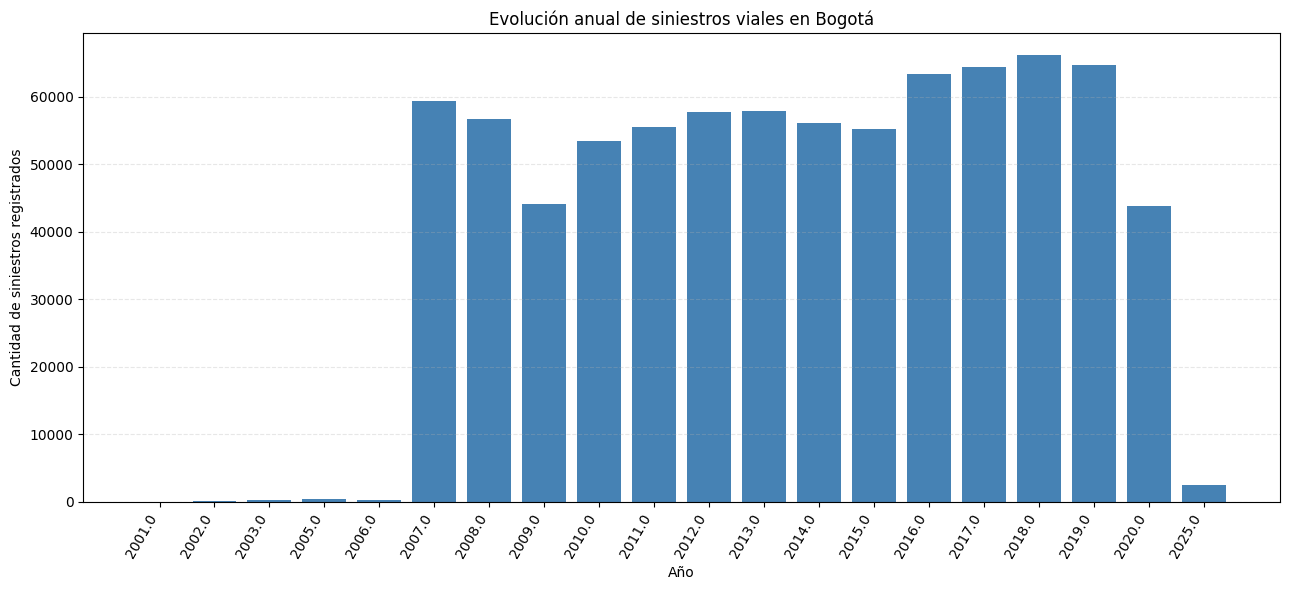

In [ ]:
#Gráfico de accidentes por año
plt.figure(figsize=(13, 6))
plt.bar(tabla_anual["Año"].astype(str),tabla_anual["Cantidad de siniestros"],color="steelblue")
plt.title("Evolución anual de siniestros viales en Bogotá")
plt.xlabel("Año")
plt.ylabel("Cantidad de siniestros registrados")
plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### 7. Conclusiones de este diagnóstico inicial

El diagnóstico inicial de la base **ACCIDENTE.csv** permite identificar un total de 906.546 registros de accidentes de tránsito en Bogotá, correspondientes al periodo comprendido entre el 15 de enero de 2001 y el 16 de octubre de 2026, sin encontrar fechas inválidas ni códigos de accidente duplicados.

En relaciòn a la calidad de los datos se identifican algunos valores vacíos en las columnas **MVINOMBRE, PK_CALZADA, CIV, CLASE_ACC, BARRIO y GRAVEDAD** aunque sus porcentajes son relativamente bajos, también se encuentran 429.097 registros con el valor SIN_NMG en MVINOMBRE, situación que requiere una revisión adicional para determinar su significado y tratamiento.

Respecto a la distribución de los accidentes tanto **Kennedy, Engativá y Suba** presentan la mayor cantidad de registros, mientras que los accidentes clasificados como solo daños representan el 61,78 % y los choques constituyen el 82,94 % de los casos, lo que permite reconocer algunas características generales de la siniestralidad vial registrada en la ciudad.

Estos resultados proporcionan una primera aproximación al comportamiento de los datos y permiten establecer una base para continuar con el análisis exploratorio, la preparación de la información y la identificación de variables que puedan contribuir al desarrollo de una solución analítica orientada a la predicción de la siniestralidad vial en Bogotá.